# Entrenamiento del detector RF-DETR Nano

Este notebook implementa el tercer experimento de detección de eventos acústicos de aves mediante bounding boxes sobre espectrogramas, se utilizará RF-DETR Nano con pesos preentrenados en COCO, adaptado a una única clase: `BIRD_EVENT`

El experimento comprende la preparación de datos, búsqueda de hiperparámetros, entrenamiento definitivo y evaluación del detector, se conservarán las particiones por grabación utilizadas en Faster R-CNN y YOLO11n. Los resultados y checkpoints se almacenarán en Google Drive.

## Preparar el entorno

In [13]:
%pip -q install "rfdetr[train]==1.12.0" "kagglehub==1.0.3"
from pathlib import Path
from importlib.metadata import version
import json
import random
import shutil
import matplotlib.pyplot as plt
import zipfile
import numpy as np
import torch
import pandas as pd
import gc
import kagglehub
from rfdetr import RFDETRNano
from rfdetr.config import RFDETRNanoConfig, TrainConfig
from rfdetr.training import RFDETRModelModule, RFDETRDataModule, build_trainer
import time
from requests.exceptions import RequestException
from rfdetr.training.callbacks.best_model import BestModelCallback, RFDETREarlyStopping

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("RF-DETR:", version("rfdetr"))
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No disponible")

RF-DETR: 1.12.0
PyTorch: 2.14.1+cu130
GPU: Tesla T4


In [2]:
from google.colab import drive
drive.mount("/content/drive")

BASE_LOCAL = Path("/content/proyecto_aves")
BASE_DRIVE = Path("/content/drive/MyDrive/Proyecto_Aves")
DIR_E3 = BASE_DRIVE / "experiments" / "detector" / "E3_RFDETR_Nano"
DIR_HPO = DIR_E3 / "hpo_v3"
DIR_FINAL = DIR_E3 / "final_v1"
RAIZ_DATOS = BASE_LOCAL / "rfdetr" / "dataset"

for carpeta in (DIR_HPO, DIR_FINAL, RAIZ_DATOS):
    carpeta.mkdir(parents=True, exist_ok=True)

print("Experimento:", DIR_E3)
print("Datos locales:", RAIZ_DATOS)

Mounted at /content/drive
Experimento: /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E3_RFDETR_Nano
Datos locales: /content/proyecto_aves/rfdetr/dataset


In [3]:
NOTEBOOK_KAGGLE = "santiagocorrea802/notebook1240c3d28f/versions/1"

archivo = Path(kagglehub.notebook_output_download(NOTEBOOK_KAGGLE, path="partes.json", output_dir=str(BASE_LOCAL / "rfdetr" / "metadatos")))

if not archivo.is_file():
    raise FileNotFoundError("no se pudo recuperar partes.json")

print("acceso publico correcto:", archivo.name)

100%|██████████| 1.78k/1.78k [00:00<00:00, 1.94MB/s]

acceso publico correcto: partes.json


## Preparacion del dataset

Se reutilizan los 46.255 espectrogramas publicados en Kaggle, distribuidos en 16 archivos zip, se mantienen las particiones originales: 38.142 imagenes de entrenamiento y 8.113 de validacion. Las etiquetas YOLO se reutilizan sin conversion a COCO.

**Descargar y extraer espectogramas**

In [4]:
ORIGEN = BASE_LOCAL / "yolo11n" / "dataset_final" / "kaggle"
DIR_ZIPS = BASE_LOCAL / "rfdetr" / "zips"
ORIGEN.mkdir(parents=True, exist_ok=True)
DIR_ZIPS.mkdir(parents=True, exist_ok=True)

for i in range(1, 17):
    nombre = f"yolo11n_completo_parte_{i:02d}"
    carpeta = ORIGEN / nombre
    esperado = 3000 if i < 16 else 1255

    if len(list(carpeta.rglob("*.png"))) == esperado and len(list(carpeta.rglob("*.txt"))) == esperado:
        print(f"Parte {i:02d}/16 disponible")
        continue

    for intento in range(1, 5):
        archivo = DIR_ZIPS / f"{nombre}.zip"

        try:
            if archivo.is_file() and not zipfile.is_zipfile(archivo):
                archivo.unlink()

            if not archivo.is_file():
                archivo = Path(kagglehub.notebook_output_download(NOTEBOOK_KAGGLE, path=archivo.name, output_dir=str(DIR_ZIPS), force_download=True))

            with zipfile.ZipFile(archivo) as z:
                rutas = [Path(info.filename) for info in z.infolist() if not info.is_dir()]
                if not rutas or any(p.is_absolute() or ".." in p.parts for p in rutas):
                    raise ValueError(f"ZIP invalido: {archivo.name}")

                incluye_carpeta = all(p.parts[0] == nombre for p in rutas)
                z.extractall(ORIGEN if incluye_carpeta else carpeta)

            if len(list(carpeta.rglob("*.png"))) != esperado or len(list(carpeta.rglob("*.txt"))) != esperado:
                raise zipfile.BadZipFile(f"Parte {i:02d} incompleta")

            archivo.unlink()
            print(f"Parte {i:02d}/16 preparada")
            break

        except (RequestException, zipfile.BadZipFile, EOFError, OSError) as e:
            archivo.unlink(missing_ok=True)
            if intento == 4:
                raise RuntimeError(f"Parte {i:02d} fallo despues de 4 intentos") from e

            print(f"Parte {i:02d}/16 fallo, reintento {intento + 1}/4")
            time.sleep(10 * intento)

print("Descarga completa")


100%|██████████| 1.14G/1.14G [00:41<00:00, 29.9MB/s]


Parte 01/16 preparada


100%|██████████| 1.14G/1.14G [00:49<00:00, 24.9MB/s]


Parte 02/16 preparada


100%|██████████| 1.14G/1.14G [00:51<00:00, 23.9MB/s]


Parte 03/16 preparada


... (22 outputs left out)

100%|██████████| 1.14G/1.14G [00:44<00:00, 27.8MB/s]


Parte 15/16 preparada


100%|██████████| 489M/489M [00:22<00:00, 22.8MB/s]


Parte 16/16 preparada
Descarga completa


**Preparar el format RF-DETR**

In [5]:
for origen_split, destino_split in (("train", "train"), ("val", "valid")):
    dir_images = RAIZ_DATOS / destino_split / "images"
    dir_labels = RAIZ_DATOS / destino_split / "labels"
    dir_images.mkdir(parents=True, exist_ok=True)
    dir_labels.mkdir(parents=True, exist_ok=True)
    total = 0

    for parte in sorted(ORIGEN.glob("yolo11n_completo_parte_*")):
        for imagen in (parte / "images" / origen_split).glob("*.png"):
            etiqueta = parte / "labels" / origen_split / f"{imagen.stem}.txt"

            if not etiqueta.is_file():
                raise FileNotFoundError(f"Etiqueta faltante: {imagen.name}")

            for fuente, destino in ((imagen, dir_images / imagen.name), (etiqueta, dir_labels / etiqueta.name)):
                if destino.exists() or destino.is_symlink():
                    if destino.resolve() != fuente.resolve():
                        raise ValueError(f"Archivo duplicado: {destino.name}")
                else:
                    destino.symlink_to(fuente)

            total += 1

    print(f"{destino_split}: {total} imagenes preparadas")

RUTA_YAML = RAIZ_DATOS / "data.yaml"
RUTA_YAML.write_text("train: train/images\nval: valid/images\nnc: 1\nnames: [BIRD_EVENT]\n", encoding="utf-8")

print("Dataset preparado:", RAIZ_DATOS)

train: 38142 imagenes preparadas
valid: 8113 imagenes preparadas
Dataset preparado: /content/proyecto_aves/rfdetr/dataset


**Validacion del dataset**

In [6]:
for split, esperado in (("train", 38142), ("valid", 8113)):
    imagenes = list((RAIZ_DATOS / split / "images").glob("*.png"))
    etiquetas = RAIZ_DATOS / split / "labels"
    if len(imagenes) != esperado:
        raise ValueError(f"{split}: {len(imagenes)} imagenes, se esperaban {esperado}")

    for imagen in imagenes:
        etiqueta = etiquetas / f"{imagen.stem}.txt"

        if not imagen.is_file() or not etiqueta.is_file():
            raise FileNotFoundError(f"Archivo faltante: {imagen.name}")

        for linea in etiqueta.read_text(encoding="utf-8").splitlines():
            valores = linea.split()

            if len(valores) != 5 or valores[0] != "0":
                raise ValueError(f"Etiqueta invalida: {etiqueta.name}")

            x, y, w, h = map(float, valores[1:])

            if not all(np.isfinite([x, y, w, h])) or not all(0 <= v <= 1 for v in (x, y, w, h)) or w <= 0 or h <= 0:
                raise ValueError(f"Bounding box invalida: {etiqueta.name}")

    print(f"{split}: {len(imagenes)} imagenes y etiquetas verificadas")

print("Validacion estructural completada")

train: 38142 imagenes y etiquetas verificadas
valid: 8113 imagenes y etiquetas verificadas
Validacion estructural completada


## Busqueda de hiperparametros

Se evaluaran seis configuraciones de tasa de aprendizaje y regularizacion sobre un subconjunto fijo del entrenamiento y validacions, se mantendran constantes la arquitectura, resolucion, batch efectivo, aumentaciones y presupuesto de entrenamiento.

La seleccion utilizara mAP@50:95 de validacion. Se registrara adicionalmente mAP@50, el conjunto de prueba permanecera excluido.

**Configuracion de HPO**

In [ ]:
HPO_CONFIG = {
    "seed": SEED,
    "train": 4000,
    "valid": 1000,
    "epochs": 15,
    "batch_size": 4,
    "grad_accum_steps": 4,
    "resolution": 384,
    "rfdetr": version("rfdetr"),
    "metrica": "val/mAP_50"
}

ENSAYOS = [
    {"lr": 5e-5, "weight_decay": 1e-4},
    {"lr": 1e-4, "weight_decay": 1e-4},
    {"lr": 2e-4, "weight_decay": 1e-4},
    {"lr": 5e-5, "weight_decay": 1e-3},
    {"lr": 1e-4, "weight_decay": 1e-3},
    {"lr": 2e-4, "weight_decay": 1e-3}
]

PLAN_HPO = {"config": HPO_CONFIG, "ensayos": ENSAYOS}
RUTA_PLAN = DIR_HPO / "plan_hpo.json"

if RUTA_PLAN.exists() and json.loads(RUTA_PLAN.read_text(encoding="utf-8")) != PLAN_HPO:
    raise ValueError("La configuracion HPO difiere de la guardada")

RUTA_PLAN.write_text(json.dumps(PLAN_HPO, indent=2), encoding="utf-8")
print(f"HPO configurada: {len(ENSAYOS)} ensayos, {HPO_CONFIG['epochs']} epocas por ensayo")

ValueError: La configuracion HPO difiere de la guardada

In [7]:
RUTA_PLAN = DIR_HPO / "plan_hpo.json"

if not RUTA_PLAN.is_file():
    raise FileNotFoundError(f"Plan HPO no encontrado: {RUTA_PLAN}")

PLAN_HPO = json.loads(RUTA_PLAN.read_text(encoding="utf-8"))
HPO_CONFIG = PLAN_HPO["config"]
ENSAYOS = PLAN_HPO["ensayos"]

print(f"HPO configurada: {len(ENSAYOS)} ensayos, {HPO_CONFIG['epochs']} epocas por ensayo")

HPO configurada: 4 ensayos, 8 epocas por ensayo


**Subconjunto HPO**

In [ ]:
RUTA_HPO_DATOS = BASE_LOCAL / "rfdetr" / "hpo_dataset"
RUTA_SELECCION = DIR_HPO / "seleccion_hpo.json"

if not (RAIZ_DATOS / "data.yaml").is_file():
    raise FileNotFoundError("Primero prepara el dataset completo")

if RUTA_SELECCION.exists():
    seleccion = json.loads(RUTA_SELECCION.read_text(encoding="utf-8"))
else:
    seleccion = {}
    for split, cantidad in (("train", 4000), ("valid", 1000)):
        imagenes = sorted((RAIZ_DATOS / split / "images").glob("*.png"))
        if len(imagenes) < cantidad:
            raise ValueError(f"Imagenes insuficientes en {split}")
        seleccion[split] = sorted(p.name for p in random.Random(SEED + (0 if split == "train" else 1)).sample(imagenes, cantidad))

    RUTA_SELECCION.write_text(json.dumps(seleccion, indent=2), encoding="utf-8")

for split, cantidad in (("train", 4000), ("valid", 1000)):
    imagenes = RUTA_HPO_DATOS / split / "images"
    etiquetas = RUTA_HPO_DATOS / split / "labels"
    imagenes.mkdir(parents=True, exist_ok=True)
    etiquetas.mkdir(parents=True, exist_ok=True)

    if len(seleccion[split]) != cantidad or len(set(seleccion[split])) != cantidad:
        raise ValueError(f"Seleccion invalida en {split}")

    for nombre in seleccion[split]:
        for fuente, destino in ((RAIZ_DATOS / split / "images" / nombre, imagenes / nombre), (RAIZ_DATOS / split / "labels" / f"{Path(nombre).stem}.txt", etiquetas / f"{Path(nombre).stem}.txt")):
            if not fuente.is_file():
                raise FileNotFoundError(f"Archivo faltante: {fuente}")
            if destino.is_symlink() or destino.exists():
                if destino.resolve() != fuente.resolve():
                    raise ValueError(f"Conflicto: {destino.name}")
            else:
                destino.symlink_to(fuente.resolve())

    if len(list(imagenes.glob("*.png"))) != cantidad:
        raise ValueError(f"Cantidad incorrecta en {split}")

    print(f"{split}: {cantidad} imagenes")

(RUTA_HPO_DATOS / "data.yaml").write_text("train: train/images\nval: valid/images\nnc: 1\nnames: [BIRD_EVENT]\n", encoding="utf-8")
print("Subconjunto HPO preparado")

**Prueba de entrenamiento**

In [ ]:
RUTA_PILOTO_DATOS = BASE_LOCAL / "rfdetr" / "piloto_dataset"
DIR_PILOTO = DIR_HPO / "piloto"

for split, cantidad in (("train", 32), ("valid", 16)):
    for tipo in ("images", "labels"):
        (RUTA_PILOTO_DATOS / split / tipo).mkdir(parents=True, exist_ok=True)

    for imagen in sorted((RUTA_HPO_DATOS / split / "images").glob("*.png"))[:cantidad]:
        etiqueta = RUTA_HPO_DATOS / split / "labels" / f"{imagen.stem}.txt"

        for fuente, destino in ((imagen, RUTA_PILOTO_DATOS / split / "images" / imagen.name), (etiqueta, RUTA_PILOTO_DATOS / split / "labels" / etiqueta.name)):
            if destino.is_symlink() or destino.exists():
                if destino.resolve() != fuente.resolve():
                    raise ValueError(f"Conflicto: {destino.name}")
            else:
                destino.symlink_to(fuente.resolve())

(RUTA_PILOTO_DATOS / "data.yaml").write_text("train: train/images\nval: valid/images\nnc: 1\nnames: [BIRD_EVENT]\n", encoding="utf-8")

if not torch.cuda.is_available():
    raise RuntimeError("Se requiere GPU CUDA")

if not (DIR_PILOTO / "checkpoint_best_total.pth").is_file():
    modelo = RFDETRNano()
    modelo.train(dataset_dir=str(RUTA_PILOTO_DATOS), output_dir=str(DIR_PILOTO), epochs=1, batch_size=4, eval_batch_size=2, grad_accum_steps=4,
                 lr=1e-4, lr_encoder=5e-5, weight_decay=1e-4, resolution=384, num_workers=2, seed=SEED, tensorboard=False, run_test=False,
                 aug_config={}, scale_jitter=False, multi_scale=False, augmentation_backend="torchvision", checkpoint_interval=1)
    del modelo
    gc.collect()
    torch.cuda.empty_cache()

if not (DIR_PILOTO / "metrics.csv").is_file():
    raise FileNotFoundError("El piloto no genero metrics.csv")

print("Piloto completado:", DIR_PILOTO)

In [8]:
def entrenar_ap50(datos, salida, epochs, lr, weight_decay, ultimo, early_stopping=False, patience=10, min_delta=0.001):
    modelo_config = RFDETRNanoConfig(num_classes=1)
    reanudacion = str(ultimo) if ultimo.is_file() else None

    if reanudacion is None and (salida / "metrics.csv").exists():
        raise RuntimeError("Existe historial de entrenamiento, pero falta last.ckpt")
    config = TrainConfig(
        dataset_dir=str(datos), output_dir=str(salida), epochs=epochs,
        batch_size=4, eval_batch_size=2, grad_accum_steps=4,
        lr=lr, lr_encoder=1.5e-4, weight_decay=weight_decay,
        num_workers=2, seed=SEED, optimizer="adamw",
        lr_scheduler="cosine", warmup_epochs=1, checkpoint_interval=epochs + 1,
        use_ema=True, eval_base_model=False, early_stopping=early_stopping,
        early_stopping_patience=patience, early_stopping_min_delta=min_delta,
        tensorboard=False, run_test=False, aug_config={},
        scale_jitter=False, multi_scale=False, augmentation_backend="torchvision", resume=reanudacion
    )

    modulo = RFDETRModelModule(modelo_config, config)
    datos_modulo = RFDETRDataModule(modelo_config, config)
    entrenador = build_trainer(config, modelo_config)

    mejores = paradas = 0
    for i, callback in enumerate(entrenador.callbacks):
        if isinstance(callback, BestModelCallback):
            entrenador.callbacks[i] = BestModelCallback(
                output_dir=str(salida), monitor_regular="val/mAP_50",
                monitor_ema="val/ema_mAP_50", run_test=False, evaluates_base_model=False
            )
            mejores += 1
        elif isinstance(callback, RFDETREarlyStopping):
            entrenador.callbacks[i] = RFDETREarlyStopping(
                patience=patience, min_delta=min_delta, use_ema=True,
                monitor_regular="val/mAP_50", monitor_ema="val/ema_mAP_50"
            )
            paradas += 1

    if mejores != 1 or paradas != int(early_stopping):
        raise RuntimeError(f"Callbacks inesperados: mejores={mejores}, paradas={paradas}")

    print("Entrenamiento iniciado (seleccion por AP50):", salida)
    print("Reanudando:", ultimo.is_file())
    try:
        entrenador.fit(modulo, datos_modulo, ckpt_path=reanudacion)
    finally:
        del entrenador, modulo, datos_modulo
        gc.collect()
        torch.cuda.empty_cache()

**Ejecutar HPO**

In [ ]:
if not (RUTA_HPO_DATOS / "data.yaml").is_file():
    raise FileNotFoundError("Dataset HPO no disponible")

if version("rfdetr") != HPO_CONFIG["rfdetr"]:
    raise RuntimeError("La version de RF-DETR cambio")

for i, parametros in enumerate(ENSAYOS, 1):
    directorio = DIR_HPO / f"ensayo_{i:02d}"
    directorio.mkdir(parents=True, exist_ok=True)

    configuracion = {**HPO_CONFIG, **parametros, "lr_encoder":1.5e-4}
    archivo_config = directorio / "configuracion.json"
    archivo_resumen = directorio / "resumen.json"
    archivo_metricas = directorio / "metrics.csv"
    checkpoint = directorio / "checkpoint_best_total.pth"

    if archivo_config.exists() and json.loads(archivo_config.read_text(encoding="utf-8")) != configuracion:
        raise ValueError(f"Configuracion diferente en ensayo {i:02d}")

    archivo_config.write_text(json.dumps(configuracion, indent=2), encoding="utf-8")

    if archivo_resumen.is_file():
        if not checkpoint.is_file():
            raise FileNotFoundError(f"Checkpoint faltante en ensayo {i:02d}")
        print(f"Ensayo {i:02d}: completado previamente")
        continue

    terminado = False
    if archivo_metricas.is_file() and checkpoint.is_file():
        historial = pd.read_csv(archivo_metricas)
        if "epoch" in historial.columns:
            terminado = pd.to_numeric(historial["epoch"], errors="coerce").max() >= HPO_CONFIG["epochs"] - 1

    if not terminado:
        ultimo = directorio / "last.ckpt"
        if archivo_metricas.exists() and not ultimo.is_file():
            raise RuntimeError(f"Ensayo {i:02d} tiene historial sin last.ckpt")
        entrenar_ap50(RUTA_HPO_DATOS, directorio, HPO_CONFIG["epochs"], parametros["lr"], parametros["weight_decay"], ultimo)

    if not archivo_metricas.is_file() or not checkpoint.is_file():
        raise FileNotFoundError(f"Resultados incompletos en ensayo {i:02d}")

    historial = pd.read_csv(archivo_metricas)
    for columna in ("epoch", "val/mAP_50_95", "val/mAP_50"):
        if columna not in historial.columns:
            raise ValueError(f"Falta {columna} en ensayo {i:02d}")
        historial[columna] = pd.to_numeric(historial[columna], errors="coerce")

    historial = historial.dropna(subset=["epoch", "val/mAP_50_95", "val/mAP_50"])
    if historial.empty:
        raise ValueError(f"Metricas invalidas en ensayo {i:02d}")

    mejor = historial.loc[historial["val/mAP_50"].idxmax()]
    resumen = {
        "ensayo": i,
        "epoca": int(mejor["epoch"]) + 1,
        "ap50_95": float(mejor["val/mAP_50_95"]),
        "ap50": float(mejor["val/mAP_50"]),
        "parametros": parametros,
        "checkpoint": str(checkpoint)
    }

    archivo_resumen.write_text(json.dumps(resumen, indent=2), encoding="utf-8")
    for nombre in ("last.ckpt", "checkpoint_best_ema.pth", "checkpoint_best_regular.pth", "last_ema.pth"):
        ruta = directorio / nombre
        if ruta.is_file():
            ruta.unlink()
    print(f"Ensayo {i:02d} | AP50:95={resumen['ap50_95']:.4f} | AP50={resumen['ap50']:.4f}")

print("HPO completada")

**Seleccionar mejor configuración**

In [ ]:
resultados = []

for i in range(1, len(ENSAYOS) + 1):
    archivo = DIR_HPO / f"ensayo_{i:02d}" / "resumen.json"
    if not archivo.is_file():
        raise FileNotFoundError(f"Ensayo {i:02d} sin resultados")
    resultados.append(json.loads(archivo.read_text(encoding="utf-8")))

tabla = pd.DataFrame([
    {
        "ensayo": r["ensayo"],
        "epoca": r["epoca"],
        "lr": r["parametros"]["lr"],
        "weight_decay": r["parametros"]["weight_decay"],
        "ap50_95": r["ap50_95"],
        "ap50": r["ap50"]
    }
    for r in resultados
]).sort_values(["ap50", "ap50_95"], ascending=False)

tabla.to_csv(DIR_HPO / "resultados_hpo.csv", index=False)
mejor = max(resultados, key=lambda r: (r["ap50"], r["ap50_95"]))

(DIR_HPO / "mejor_config.json").write_text(json.dumps(mejor, indent=2), encoding="utf-8")

display(tabla)
print(f"Mejor ensayo: {mejor['ensayo']:02d}")
print(f"Mejor AP50: {mejor['ap50']:.4f}")
print(f"AP50:95 correspondiente: {mejor['ap50_95']:.4f}")

**Convergencia**

In [ ]:
import matplotlib.pyplot as plt

diagnostico = []
fig, ax = plt.subplots(figsize=(9, 5))

for i in range(1, len(ENSAYOS) + 1):
    ruta = DIR_HPO / f"ensayo_{i:02d}" / "metrics.csv"
    df = pd.read_csv(ruta)
    columnas = ["epoch", "val/mAP_50_95", "val/mAP_50"]

    if not set(columnas).issubset(df.columns):
        raise ValueError(f"Metricas incompletas en ensayo {i:02d}")

    datos = df[columnas].apply(pd.to_numeric, errors="coerce")
    datos = datos.dropna().sort_values("epoch").drop_duplicates("epoch", keep="last")

    if len(datos) != HPO_CONFIG["epochs"]:
        raise ValueError(f"Ensayo {i:02d}: {len(datos)} epocas validadas")

    mejor_idx = datos["val/mAP_50"].idxmax()
    mejor_epoca = int(datos.loc[mejor_idx, "epoch"])
    ultima_epoca = int(datos["epoch"].max())

    diagnostico.append({
        "ensayo": i,
        "mejor_epoca_registrada": mejor_epoca,
        "ultima_epoca_registrada": ultima_epoca,
        "ap50": float(datos.loc[mejor_idx, "val/mAP_50"]),
        "mejor_en_ultima_epoca": mejor_epoca == ultima_epoca
    })

    ax.plot(datos["epoch"], datos["val/mAP_50"], label=f"Ensayo {i:02d}")

ax.set(xlabel="Epoca registrada", ylabel="AP@50", title="Convergencia de la HPO")
ax.grid(alpha=0.3)
ax.legend()
plt.show()
df_diagnostico = pd.DataFrame(diagnostico)
display(df_diagnostico)

if df_diagnostico["mejor_en_ultima_epoca"].any():
    print("Advertencia: algunos ensayos alcanzaron su mejor resultado en la ultima epoca")
else:
    print("Ningun ensayo obtuvo su mejor resultado en la ultima epoca")

**Configurar entrenamiento**

Para el dataset completo tenemos 38.142 espectrogramas de entrenamiento. La guía oficial de RF-DETR recomienda orientativamente 20–30 épocas para conjuntos superiores a 10.000 imágenes. Utilizaremos 30 como límite superior documentado, no como un valor óptimo demostrado.
RF-DETR

La parada anticipada utilizará los valores de referencia de RF-DETR: paciencia de 10 épocas y mejora mínima de 0,001 en mAP. Estos también son criterios heurísticos, pero ahora están especificados y respaldados por la documentación.
RF-DETR

In [9]:
RUTA_MEJOR_HPO = DIR_HPO / "mejor_config.json"
mejor = json.loads(RUTA_MEJOR_HPO.read_text(encoding="utf-8"))

if version("rfdetr") != HPO_CONFIG["rfdetr"]:
    raise RuntimeError("La version de RF-DETR difiere de la utilizada en HPO")

CONFIG_FINAL = {
    "modelo": "RFDETRNano",
    "rfdetr": version("rfdetr"),
    "hpo_ensayo": mejor["ensayo"],
    "train": 38142,
    "valid": 8113,
    "epochs": 30,
    "early_stopping_patience": 10,
    "early_stopping_min_delta": 0.001,
    "batch_size": HPO_CONFIG["batch_size"],
    "grad_accum_steps": HPO_CONFIG["grad_accum_steps"],
    "resolution": HPO_CONFIG["resolution"],
    "lr": mejor["parametros"]["lr"],
    "lr_encoder": 1.5e-4,
    "weight_decay": mejor["parametros"]["weight_decay"],
    "lr_scheduler": "cosine",
    "warmup_epochs": 1,
    "seed": SEED,
    "metrica": "val/mAP_50"
}

RUTA_CONFIG_FINAL = DIR_FINAL / "configuracion.json"

if RUTA_CONFIG_FINAL.exists() and json.loads(RUTA_CONFIG_FINAL.read_text(encoding="utf-8")) != CONFIG_FINAL:
    raise ValueError("La configuracion definitiva difiere de la guardada")

RUTA_CONFIG_FINAL.write_text(json.dumps(CONFIG_FINAL, indent=2), encoding="utf-8")

print("Configuracion definitiva preparada")
print(f"Ensayo HPO seleccionado: {CONFIG_FINAL['hpo_ensayo']:02d}")
print(f"Epocas maximas: {CONFIG_FINAL['epochs']}")
print(f"Learning rate: {CONFIG_FINAL['lr']}")
print(f"Weight decay: {CONFIG_FINAL['weight_decay']}")

Configuracion definitiva preparada
Ensayo HPO seleccionado: 03
Epocas maximas: 30
Learning rate: 0.0002
Weight decay: 0.0001


## Entrenamiento

In [11]:
RUTA_LAST_FINAL = DIR_FINAL / "last.ckpt"
RUTA_BEST_FINAL = DIR_FINAL / "checkpoint_best_total.pth"
RUTA_METRICAS_FINAL = DIR_FINAL / "metrics.csv"
RUTA_ESTADO_FINAL = DIR_FINAL / "estado_final.json"

if (not RUTA_ESTADO_FINAL.is_file() and RUTA_METRICAS_FINAL.is_file() and not RUTA_LAST_FINAL.is_file()):
    raise RuntimeError("Existe un entrenamiento incompleto sin checkpoint de recuperacion")

if not (RAIZ_DATOS / "data.yaml").is_file():
    raise FileNotFoundError("Dataset completo no disponible")

if not torch.cuda.is_available():
    raise RuntimeError("Se requiere GPU CUDA")

if RUTA_ESTADO_FINAL.is_file():
    if not RUTA_BEST_FINAL.is_file():
        raise FileNotFoundError("Falta el mejor checkpoint")
    print("Entrenamiento definitivo completado previamente")
else:
    entrenar_ap50(RAIZ_DATOS, DIR_FINAL, CONFIG_FINAL["epochs"], CONFIG_FINAL["lr"], CONFIG_FINAL["weight_decay"], RUTA_LAST_FINAL, early_stopping=True,
                  patience=CONFIG_FINAL["early_stopping_patience"], min_delta=CONFIG_FINAL["early_stopping_min_delta"])

    if not RUTA_BEST_FINAL.is_file() or not RUTA_METRICAS_FINAL.is_file():
        raise FileNotFoundError("Entrenamiento sin checkpoint o metricas finales")

    RUTA_ESTADO_FINAL.write_text(json.dumps({"finalizado": True}, indent=2), encoding="utf-8")
    print("Entrenamiento definitivo completado")

[2026-11-13 21:22:12] [INFO] rf-detr - File rf-detr-nano.pth already exists with correct MD5 hash.


[2026-11-13 21:22:16] [WARNING] rf-detr - Checkpoint has 90 classes but model is configured for 1. The detection head will be re-initialized to 1 classes.
INFO:pytorch_lightning.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Entrenamiento iniciado (seleccion por AP50): /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E3_RFDETR_Nano/final_v1
Reanudando: True
creating index...
index created!


INFO:pytorch_lightning.utilities.rank_zero:Restoring states from the checkpoint path at /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E3_RFDETR_Nano/final_v1/last.ckpt


creating index...
index created!
[2026-11-13 21:23:19] [INFO] rf-detr - Resuming the optimizer with lr_vit_layer_decay=0.8, lr_component_decay=0.7 from the checkpoint.


INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.utilities.rank_zero:Loading `train_dataloader` to estimate number of stepping batches.


... (3 outputs left out)

[2026-11-13 21:58:31] [INFO] rf-detr - Skipping validation-loss computation: compute_val_loss='auto' found no scheduler or callback monitoring 'val/loss', so no 'val/loss' metric is logged this run. Set compute_val_loss=True to log it every validation epoch (for example to read the curve from metrics.csv, TensorBoard, or Weights & Biases).


Output()

INFO:pytorch_lightning.callbacks.early_stopping:Monitored metric __rfdetr_effective_map__ did not improve in the last 10 records. Best score: 0.469. Signaling Trainer to stop.


[2026-11-13 23:21:10] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.0000, ema=0.4687)
Entrenamiento definitivo completado


## Resultado del entrenamiento

Mejor epoca: 4
Mejor AP50: 0.4687
AP50:95 correspondiente: 0.2113
Epocas validadas: 14


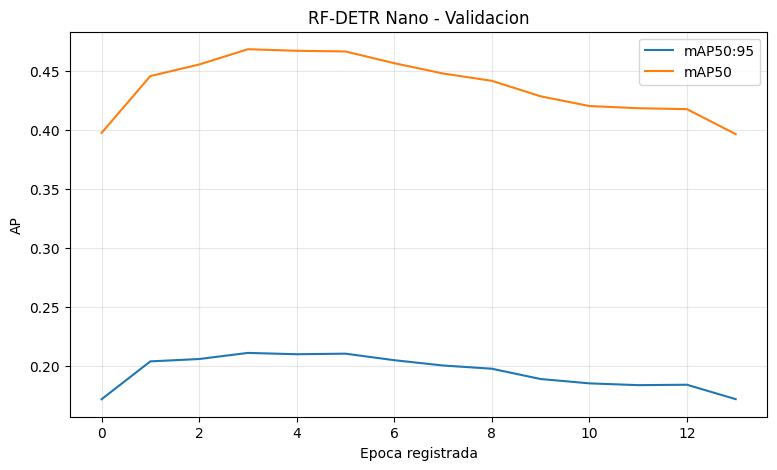

In [14]:
if not RUTA_BEST_FINAL.is_file() or not RUTA_METRICAS_FINAL.is_file():
    raise FileNotFoundError("Entrenamiento definitivo incompleto")

df = pd.read_csv(RUTA_METRICAS_FINAL)
columnas = ["epoch", "val/mAP_50_95", "val/mAP_50"]
if not set(columnas).issubset(df.columns):
    raise ValueError("Faltan metricas de validacion")

historial = df[columnas].apply(pd.to_numeric, errors="coerce")
historial = historial.dropna().sort_values("epoch").drop_duplicates("epoch", keep="last")
if historial.empty:
    raise ValueError("No hay resultados validos")

mejor_fila = historial.loc[historial["val/mAP_50"].idxmax()]

resultado_final = {
    "mejor_epoca_registrada": int(mejor_fila["epoch"]),
    "ap50_95": float(mejor_fila["val/mAP_50_95"]),
    "ap50": float(mejor_fila["val/mAP_50"]),
    "epocas_validadas": len(historial),
    "checkpoint": str(RUTA_BEST_FINAL)
}

(DIR_FINAL / "resultados_validacion.json").write_text(json.dumps(resultado_final, indent=2), encoding="utf-8")

print(f"Mejor epoca: {resultado_final['mejor_epoca_registrada'] + 1}")
print(f"Mejor AP50: {resultado_final['ap50']:.4f}")
print(f"AP50:95 correspondiente: {resultado_final['ap50_95']:.4f}")
print(f"Epocas validadas: {resultado_final['epocas_validadas']}")

plt.figure(figsize=(9, 5))
plt.plot(historial["epoch"], historial["val/mAP_50_95"], label="mAP50:95")
plt.plot(historial["epoch"], historial["val/mAP_50"], label="mAP50")
plt.xlabel("Epoca registrada")
plt.ylabel("AP")
plt.title("RF-DETR Nano - Validacion")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [1]:
from google.colab import drive, runtime
import json

# Archivos necesarios para conservar el experimento
archivos_requeridos = [
    DIR_HPO / "mejor_config.json",
    DIR_HPO / "resultados_hpo.csv",
    DIR_FINAL / "configuracion.json",
    DIR_FINAL / "estado_final.json",
    DIR_FINAL / "last.ckpt",
    DIR_FINAL / "checkpoint_best_total.pth",
    DIR_FINAL / "metrics.csv",
    DIR_FINAL / "resultados_validacion.json",
]

# Comprobar que todos existen y contienen datos
faltantes = [
    str(ruta)
    for ruta in archivos_requeridos
    if not ruta.is_file() or ruta.stat().st_size == 0
]

if faltantes:
    raise RuntimeError(
        "No se desconectara Colab. Faltan archivos:\n"
        + "\n".join(faltantes)
    )

# Comprobar que el entrenamiento fue marcado como finalizado
estado = json.loads((DIR_FINAL / "estado_final.json").read_text(encoding="utf-8"))

if estado.get("finalizado") is not True:
    raise RuntimeError("El entrenamiento no figura como finalizado.")

print("Entrenamiento y resultados verificados.", flush=True)
print("Sincronizando archivos con Google Drive...", flush=True)

# Esperar la sincronización de todas las escrituras pendientes
drive.flush_and_unmount()

print("Google Drive sincronizado correctamente.", flush=True)
print("Liberando el entorno de Colab y la GPU...", flush=True)

runtime.unassign()


NameError: name 'DIR_HPO' is not defined